## Week 2 Day 2 - Orchestration

Our first Agentic Framework project!!

### Part 1: Email Setup

### Part 2: Orchestrating by code

### Part 3: Orchestrating by LLMs

- 3a: via Tools
- 3b: via Handoffs

## Part 1: Email Setup

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/stop.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#ff7800;">IMPORTANT PLEASE READ - Sending Emails</h2>
            <span style="color:#ff7800;">We are going to write an agent that sends emails. The best way to do this is with an email provider
            like SendGrid or Resend. But this requires a fair amount of heavy-lifting: you need to send from a proper email host where you own the domain and you can prove it with DNS records. It's quite a hassle.<br/><br/>
            So we're going to do it the free & simple way: using SMTP server configuration to send direct from your email. It's an easy setup, but it's not as powerful (eg you can't receive emails). If you'd like to take this further, use SendGrid or Resend instead..<br/><br/>
            And actually the email send is optional. We're doing this to demonstrate an Agent sending emails. The important part is the Agent work, not the email sending. Feel free to swap out the function for a Pushover push if you'd prefer.
            </span>
        </td>
    </tr>
</table>

## Setting up to send emails from your SMTP server

### STEP 1: Determining your SMTP Server

Either google or ask ChatGPT / Claude for the SMTP server for your email. Here are some common ones. Some email providers might not have SMTP servers enabled (eg Microsoft 365 for work/school).

Google: smtp.gmail.com  
Outlook.com / Hotmail / Live: smtp-mail.outlook.com  
Microsoft 365: smtp.office365.com  
iCloud Mail: smtp.mail.me.com  

Add to your .env file:  

`EMAIL_SMTP_SERVER=xxxx`

### STEP 2: Obtain an app specific password

Google how to do this for your email provider. For gmail, you need to have 2-step verification on. Then visit this page:

https://myaccount.google.com/apppasswords

Give it any name; copy the password and add it to your .env file, removing the spaces that it adds. (It should be 16 characters, no spaces.)

`EMAIL_APP_PASSWORD=xxxx`

### STEP 3: Add in your email address:

`EMAIL_ADDRESS=xxx`

Remember to Save the .env file!

In [ ]:
from dotenv import load_dotenv
import requests
from agents import Agent, Runner, trace, function_tool, ModelSettings
from agents.extensions.visualization import draw_graph
from openai.types.responses import ResponseTextDeltaEvent
import os
import asyncio
import smtplib
from email.message import EmailMessage
load_dotenv(override=True)
MODEL_NAME = "gpt-5.4-mini"

In [ ]:
EMAIL_ADDRESS = os.getenv("EMAIL_ADDRESS")
EMAIL_SMTP_SERVER = os.getenv("EMAIL_SMTP_SERVER")
EMAIL_APP_PASSWORD = os.getenv("EMAIL_APP_PASSWORD")

if EMAIL_ADDRESS:
    print("Email address is set")
else:
    print("Email address is not set")

if EMAIL_SMTP_SERVER:
    print("SMTP server is set")
else:
    print("SMTP server is not set")

if EMAIL_APP_PASSWORD:
    print("App password is set")
else:
    print("App password is not set")

USE_EMAIL = EMAIL_ADDRESS and EMAIL_SMTP_SERVER and EMAIL_APP_PASSWORD

if USE_EMAIL:
    print("Email is set up and we will try using it")
else:
    print("Email is not set up; we will send push notifications instead")

Email address is set
SMTP server is set
App password is set
Email is set up and we will try using it


In [4]:
# Here we go

def send_email(subject, text_body, html_body):
    msg = EmailMessage()
    msg["From"] = EMAIL_ADDRESS
    msg["To"] = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)
    msg.add_alternative(html_body, subtype="html")

    with smtplib.SMTP(EMAIL_SMTP_SERVER, 587) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)

In [5]:
send_email("Testing testing 123", "Fingers crossed..", "<html><body><strong>Fingers</strong> crossed..</body></html>")

### If this didn't work, then uncomment the below so that we don't use emails

In [ ]:
# USE_EMAIL = False

### Our fallback strategy - send a push

In [6]:
pushover_user = os.getenv("PUSHOVER_USER")
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_url = "https://api.pushover.net/1/messages.json"

if pushover_user:
    if pushover_user.startswith("u"):
        print("Pushover user found and looks good")
    else:
        print("Pushover user found but doesn't start with u")
else:
    print("Pushover user not found")

if pushover_token:
    if pushover_token.startswith("a"):
        print("Pushover token found and looks good")
    else:
        print("Pushover token found but doesn't start with a")
else:
    print("Pushover token not found")

Pushover user found and looks good
Pushover token found and looks good


In [7]:
def push(message):
    print(f"Push: {message}")
    payload = {"user": pushover_user, "token": pushover_token, "message": message}
    requests.post(pushover_url, data=payload)

In [8]:
def send_message(subject, text_body, html_body):
    if USE_EMAIL:
        send_email(subject, text_body, html_body)
    else:
        push(f"Subject: {subject}\n\n{text_body}")

### OK Now everything should work!

In [9]:
send_message("Big news", "Communications are a go!", "<html><body>Communications are a <strong>go!</strong></body></html>")

## Agent Orchestration

There are 2 models for Agent Orchestration; by code and by LLMs.

By code: more predictable and deterministic.

By LLMs: more powerful.

An excellent write-up is here:

https://openai.github.io/openai-agents-python/multi_agent/

We will start with by Code.

## Part 2: Orchestrating by Code

In [10]:
intro = """
You are a sales agent working for ComplAI,
a company that provides a SaaS tool for ensuring SOC2 compliance and preparing for audits, powered by AI.
You write emails.
"""

instructions1 = intro + "Your email style is professional, serious, with gravitas and credibility."
instructions2 = intro + "Your email style is witty, engaging, and humorous."
instructions3 = intro + "Your email style is concise, to the point, in the style of a busy senior executive."

In [11]:
sales_agent1 = Agent(name="Professional Sales Agent", instructions=instructions1, model=MODEL_NAME)
sales_agent2 = Agent(name="Humorous Sales Agent", instructions=instructions2, model=MODEL_NAME)
sales_agent3 = Agent(name="Executive Sales Agent", instructions=instructions3, model=MODEL_NAME)


In [12]:

result = Runner.run_streamed(sales_agent1, input="Write a cold sales email")
async for event in result.stream_events():
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent):
        print(event.data.delta, end="", flush=True)

Subject: Simplify SOC 2 readiness without slowing the team down

Hi [First Name],

I’m reaching out from ComplAI. We help teams prepare for SOC 2 and stay audit-ready with an AI-powered platform that reduces the manual work involved in compliance.

For most companies, SOC 2 becomes a drain on engineering, operations, and leadership time. Evidence collection, control tracking, and auditor preparation all add up quickly. ComplAI is designed to make that process more structured, faster, and easier to manage.

With ComplAI, you can:
- centralize compliance tasks and evidence
- track readiness across controls in real time
- reduce back-and-forth during audit preparation
- keep the team aligned without relying on spreadsheets and ad hoc follow-up

If SOC 2 is on your roadmap this quarter, I’d be glad to share how teams are using ComplAI to move faster with less overhead.

Would a brief conversation next week be worthwhile?

Best,  
[Your Name]  
ComplAI

In [13]:
message = "Write a cold sales email"

with trace("Parallel cold emails"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )

outputs = [result.final_output for result in results]

for output in outputs:
    print(output + "\n\n")


Subject: Simplifying SOC 2 readiness without slowing your team down

Hi [First Name],

I’m reaching out from ComplAI. We help teams streamline SOC 2 compliance and get audit-ready faster using AI-powered workflows that reduce manual work and keep evidence collection organized.

For many companies, the compliance process becomes a drain on engineering, security, and operations. ComplAI is designed to make that work more manageable by helping teams:

- centralize evidence collection
- track readiness gaps against SOC 2 requirements
- prepare for audits with less back-and-forth
- reduce the operational burden on internal teams

If SOC 2 is on your roadmap this quarter, I’d be glad to share how ComplAI can support your team and what the process typically looks like.

Would you be open to a brief conversation next week?

Best,  
[Your Name]  
ComplAI


Subject: SOC 2, minus the spreadsheet sorcery

Hi {{FirstName}},

Quick question: how’s your SOC 2 prep going?  
If the answer is somewhere 

In [14]:
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Do not give an explanation; reply with the selected email only.
"""

sales_picker = Agent(name="Sales_picker", instructions=decision, model=MODEL_NAME)


In [15]:
message = "Write a cold sales email"

with trace("Sales selection workflow"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [result.final_output for result in results]

    emails = "Cold sales emails:\n\n" + "\n\nEmail:\n\n".join(outputs)

    best = await Runner.run(sales_picker, emails)

    print(f"Best sales email:\n{best.final_output}")


Best sales email:
Subject: SOC 2 prep without the scramble

Hi [First Name],

Most teams don’t struggle with SOC 2 because they lack effort — they struggle because evidence collection, control tracking, and audit prep turn into a manual mess.

ComplAI helps teams stay audit-ready year-round with an AI-powered platform for SOC 2 compliance:
- centralizes evidence
- tracks control ownership
- flags gaps before the auditor does
- reduces the back-and-forth during prep

If SOC 2 is on your roadmap this quarter, I’d be happy to show you how teams use ComplAI to cut the chaos and move faster.

Open to a quick 15-minute conversation?

Best,
[Your Name]


Now go and check out the trace:

https://platform.openai.com/traces

### Now we will add a tool to the mix.

In [16]:
@function_tool
def send_email_tool(subject: str, text_body: str, html_body: str) -> str:
    """
    Send out an email with the given subject and body to all sales prospects

    Args:
        subject: The subject of the email
        text_body: The body of the email as plain text
        html_body: The HTML body of the email
    """
    send_message(subject, text_body, html_body)
    return "Email sent successfully"

### This has automatically been converted into a tool, with the boilerplate json created

In [28]:
send_email_tool.params_json_schema

{'properties': {'subject': {'description': 'The subject of the email',
   'title': 'Subject',
   'type': 'string'},
  'text_body': {'description': 'The body of the email as plain text',
   'title': 'Text Body',
   'type': 'string'},
  'html_body': {'description': 'The HTML body of the email',
   'title': 'Html Body',
   'type': 'string'}},
 'required': ['subject', 'text_body', 'html_body'],
 'title': 'send_email_tool_args',
 'type': 'object',
 'additionalProperties': False}

In [17]:
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Then use your tool to send the email.
"""

require_tool = ModelSettings(tool_choice="required")

sales_sender = Agent(name="Sales Sender", instructions=decision, model=MODEL_NAME, tools=[send_email_tool], model_settings=require_tool)

In [18]:
message = "Write a cold sales email"

with trace("Sales selection workflow with sending"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [result.final_output for result in results]

    emails = "Cold sales emails:\n\n" + "\n\nEmail:\n\n".join(outputs)

    response = await Runner.run(sales_sender, emails)

    print(f"Final response:\n{response.final_output}")

Final response:
Done — I chose and sent the second email (“SOC 2 compliance, but make it less painful”).


### Did that work?!

See the traces for more! This is a great way to debug. Smaller models might require more time and experimentation.

https://platform.openai.com/traces

## Part 3: Orchestrating by LLMs

### 3a: via Tools

The simplest way to have 1 Agent choose to invoke another is by treating it as a tool call.

The OpenAI Agents SDK gives a very simple way to do this.

This works best when the flow is:

Agent A -> Agent B -> Agent A

And for the classic "Planning Agent" situation.

In [19]:
description = "Use this tool to write a sales email. In the input, just instruct it to write a sales email."

tool1 = sales_agent1.as_tool(tool_name="sales_email_writer_1", tool_description=description)
tool1

FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x7e945b76bb30>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False)

### So now we can gather all the tools together:

A tool for each of our 3 email-writing agents

And a tool for our function to send emails

In [20]:
tool1 = sales_agent1.as_tool(tool_name="sales_email_writer_1", tool_description=description)
tool2 = sales_agent2.as_tool(tool_name="sales_email_writer_2", tool_description=description)
tool3 = sales_agent3.as_tool(tool_name="sales_email_writer_3", tool_description=description)

tools = [tool1, tool2, tool3, send_email_tool]

tools

[FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x7e946411eb40>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False),
 FunctionTool(name='sales_email_writer_2', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', '

## And now it's time for our Sales Manager - our planning agent

In [21]:
instructions = """
You are a Sales Manager at ComplAI. Your goal is to find the single best cold sales email using the sales_writer tools.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to generate different email drafts.
Just instruct each to write a sales email; no further details are needed.
Do not proceed until all three drafts are ready, one from each tool.

2. Evaluate and Select: Choose the email that is the most memorable and likely to make the reader smile.

3. Use your tool to send the best email (and only the best email) to the user. Only send 1 email.
"""

sales_manager = Agent(name="Sales Manager", instructions=instructions, tools=tools, model=MODEL_NAME)


### Optional: a diagram of our Sales Manager

The next cell draws a picture of the Sales Manager and its tools, using a free program called Graphviz. This step is optional! If you skip it, the two `draw_graph` cells will show an error. That's fine; just carry on with the lab.

To install Graphviz, open the Terminal in Cursor with Ctrl+backtick (`` ` ``) and run the command for your computer:

- Mac: `brew install graphviz` (you'll need Homebrew from https://brew.sh)
- Windows: `winget install graphviz`, then restart Cursor and run this notebook again from the top
- Linux: `sudo apt install graphviz`

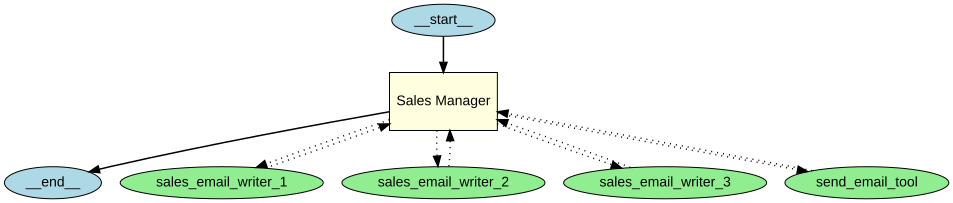

In [22]:
draw_graph(sales_manager)

In [23]:
with trace("Sales manager"):
    result = await Runner.run(sales_manager, task)

In [25]:
import json, difflib

names = {
    "sales_email_writer_1": "Professional",
    "sales_email_writer_2": "Humorous",
    "sales_email_writer_3": "Executive",
}
calls, drafts, sent = {}, {}, None

for item in result.new_items:
    raw = item.raw_item
    if item.type == "tool_call_item":
        calls[raw.call_id] = raw.name
        if raw.name == "send_email_tool":
            sent = json.loads(raw.arguments)
    elif item.type == "tool_call_output_item":
        call_id = raw["call_id"] if isinstance(raw, dict) else raw.call_id
        tool = calls.get(call_id)
        if tool in names:
            drafts[tool] = str(item.output)

if sent is None:
    print("No email was sent")
else:
    print("Subject:", sent["subject"], "\n")
    scores = {t: difflib.SequenceMatcher(None, d, sent["text_body"]).ratio() for t, d in drafts.items()}
    best = max(scores, key=scores.get)
    for t, s in scores.items():
        print(f"{names[t]:<13} {s:.0%} match" + ("   <-- sent" if t == best else ""))


Subject: Make SOC 2 feel less like a tax audit from the future 

Professional  8% match
Humorous      60% match   <-- sent
Executive     11% match


## Remember to check the trace

https://platform.openai.com/traces

And then check your email!! Also look in your Junk / Spam folder - after all, this is basically a spam message..


<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/stop.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#ff7800;">Unreliable results?</h2>
            <span style="color:#ff7800;">This is par for the course with Agentic AI, and particularly with Orchestrating by LLM.
            To resolve it, you'll need to experiment and iterate with the prompts. Particularly with smaller models, more experiments
            may be needed to get reliable outcomes.
            </span>
        </td>
    </tr>
</table>

## Part 3: Orchestrating by LLMs

### 3a: via Handoffs

I am not a fan of handoffs. They seem very unreliable. They're not used consistently by other frameworks.

Behind the scenes, OpenAI Agents SDK has implemented these with Tools anyway.

### Handoffs represent a way an agent can delegate to an agent, passing control to it

Handoffs and Agents-as-tools are similar:

In both cases, an Agent can collaborate with another Agent

With tools, control passes back

A -> B -> A

With handoffs, control passes across

A -> B

In [26]:

instructions = """
You are a Sales Manager at ComplAI. You get your sales team to draft emails, then send them all to a sales picker.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to generate different email drafts.
Just instruct each to write a sales email; no further details are needed.
Do not proceed until all three drafts are ready, one from each tool.

2. Handoff to the sales sender to choose and send the best email.
"""

tools = [tool1, tool2, tool3]
handoffs = [sales_sender]

sales_manager = Agent(name="Sales Manager", instructions=instructions, tools=tools, handoffs=handoffs, model=MODEL_NAME)


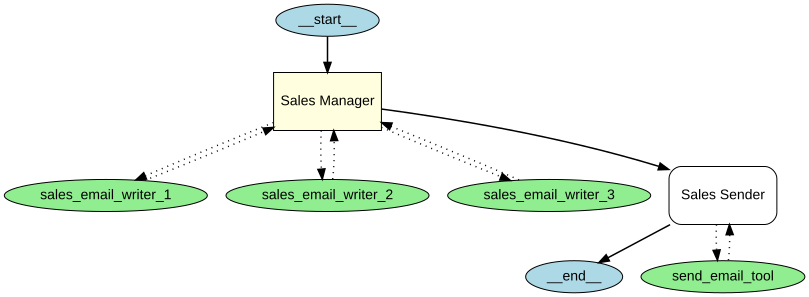

In [27]:
draw_graph(sales_manager)

In [28]:
with trace("Sales manager"):
    result = await Runner.run(sales_manager, task)

Tool name 'transfer_to_Sales Sender' contains invalid characters for function calling and has been transformed to 'transfer_to_sales_sender'. Please use only letters, digits, and underscores to avoid potential naming conflicts.
Tool name 'transfer_to_Sales Sender' contains invalid characters for function calling and has been transformed to 'transfer_to_sales_sender'. Please use only letters, digits, and underscores to avoid potential naming conflicts.
Tool name 'transfer_to_Sales Sender' contains invalid characters for function calling and has been transformed to 'transfer_to_sales_sender'. Please use only letters, digits, and underscores to avoid potential naming conflicts.


### Remember to check the trace

https://platform.openai.com/traces

And then check your email!!

Note that handoffs can be unrealiable and a little bit frustrating. I needed to force the tool use otherwise this didn't work. If you don't get reliable behavior, try iterating on the prompts - or use a larger model. And enjoy the process; this is what Agentic AI is all about!

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/exercise.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#ff7800;">Exercise</h2>
            <span style="color:#ff7800;">Try extending with some more orchestration - perhaps another iteration of the email to refine it. 
            Use Orchestrating via Code and Orchestrating via LLMs.  
            HARD CHALLENGE: switch to using a professional email provider like SendGrid or Resend. Then handle the user replying. 
            Then have the SDR respond to keep the conversation going!
            </span>
        </td>
    </tr>
</table>

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/business.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#00bfff;">Commercial implications</h2>
            <span style="color:#00bfff;">This is immediately applicable to Sales Automation; but more generally this could be applied to  end-to-end automation of any business process through conversations and tools. Think of ways you could apply an Agent solution
            like this in your day job.
            </span>
        </td>
    </tr>
</table>

## My Exercise: Critique & Revise Loop

Extending the lab with one more iteration: after picking the best draft, a **Critic** gives feedback and a **Reviser** applies it.

We build the same flow two ways:
- **Step 2a, orchestration by code:** a Python loop runs a fixed number of critique/revise rounds
- **Step 2b, orchestration by LLM:** the Sales Manager reads the feedback and decides whether another revision is worth it

### Step 1: The Critic and the Reviser

In [29]:
critic = Agent(
    name="Email Critic",
    instructions="You are a skeptical CTO at a 50-person SaaS startup who gets 30 cold emails a day. "
                 "Critique the cold email you are given. Reply with 2-3 specific, actionable fixes "
                 "that would make you more likely to reply. Be brief.",
    model=MODEL_NAME,
)

reviser = Agent(
    name="Email Reviser",
    instructions=intro + "You revise a cold email using the feedback given. Return only the revised email.",
    model=MODEL_NAME,
)

### Step 2a: Orchestrating by Code

Parallel drafts → picker → a fixed number of critique/revise rounds → send.

Our code decides everything here: how many rounds to run and what gets passed between agents.

In [30]:
async def refine(email, rounds=2):
    """Run a fixed number of critique -> revise rounds."""
    for i in range(1, rounds + 1):
        feedback = (await Runner.run(critic, email)).final_output
        print(f"--- Round {i} feedback ---\n{feedback}\n")
        revision = await Runner.run(reviser, f"Email:\n{email}\n\nFeedback:\n{feedback}")
        email = revision.final_output
    return email

In [31]:
message = "Write a cold sales email"

with trace("Draft, pick, refine loop (code)"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [result.final_output for result in results]
    emails = "Cold sales emails:\n\n" + "\n\nEmail:\n\n".join(outputs)

    best = await Runner.run(sales_picker, emails)
    print(f"=== Picked draft ===\n{best.final_output}\n")

    final_email = await refine(best.final_output)
    print(f"=== Final email ===\n{final_email}")

    # Reuse the Sales Sender (tool_choice="required") to format and send it
    await Runner.run(sales_sender, "Cold sales emails:\n\nEmail:\n\n" + final_email)

=== Picked draft ===
Subject: SOC 2 prep without the usual drag

Hi [First Name],

I’m reaching out because ComplAI helps teams get SOC 2 audit-ready faster, with less manual work and fewer surprises.

We use AI to help automate evidence collection, map controls, and keep compliance tasks moving so your team doesn’t get buried in spreadsheets and follow-ups.

If SOC 2 is on your roadmap this quarter, I’d be glad to show you how it works.

Open to a quick 15-minute intro next week?

Best,
[Your Name]  
ComplAI

--- Round 1 feedback ---
A few fixes would make this feel less like a generic pitch:

1. Be specific about why you’re emailing me.  
   Add a trigger like “noticed you’re hiring for eng/security” or “saw you’re preparing for a SOC 2 audit.” Right now it reads like a mass email.

2. Say what’s actually different.  
   “AI” and “less manual work” are vague. Give one concrete outcome, like “cut evidence requests from 40 emails to one dashboard” or “helped X-company finish in Y weeks

### Step 2b: Orchestrating by LLM

Same agents, now exposed as tools. The Sales Manager reads the critic's feedback and decides whether to revise again.

In [ ]:
refine_tools = [
    tool1, tool2, tool3,
    critic.as_tool(tool_name="critique_email",
                   tool_description="Get specific feedback on a cold email. Pass in the full email."),
    reviser.as_tool(tool_name="revise_email",
                    tool_description="Revise a cold email. Pass in the full email AND the feedback to apply."),
    send_email_tool,
]

refine_instructions = """
You are a Sales Manager at ComplAI. You make sure only high-quality cold emails go out.
"""

refine_task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to get one draft each.
Do not proceed until all three drafts are ready.

2. Select: Pick the single best draft.

3. Refine: Use critique_email on it, then use revise_email with the email and the feedback.
Critique the revised version. If the feedback still points to significant problems, revise once more.
Do at most 2 revisions in total.

4. Send: Use send_email_tool to send the final version. Send only 1 email.
"""

refine_manager = Agent(name="Refining Sales Manager", instructions=refine_instructions,
                       tools=refine_tools, model=MODEL_NAME)

In [ ]:
draw_graph(refine_manager)

In [ ]:
with trace("Draft, pick, refine loop (LLM)"):
    result = await Runner.run(refine_manager, refine_task)

### What did the manager actually do?

List every tool call in order to check whether it followed the rules.

In [ ]:
calls = {}
for item in result.new_items:
    raw = item.raw_item
    if item.type == "tool_call_item":
        calls[raw.call_id] = raw.name
        print(f"-> {raw.name}")
    elif item.type == "tool_call_output_item":
        call_id = raw["call_id"] if isinstance(raw, dict) else raw.call_id
        if calls.get(call_id) == "critique_email":
            print(f"   feedback: {str(item.output)[:200]}...")

tool_names = list(calls.values())
print(f"\nCritiques: {tool_names.count('critique_email')}, "
      f"Revisions: {tool_names.count('revise_email')}, "
      f"Emails sent: {tool_names.count('send_email_tool')}")

### Step 3: Compare

I ran 2a and 2b 3 times each with `gpt-5.4-mini`.

| | 2a: by code | 2b: by LLM |
|---|---|---|
| Critique → revise rounds | Always 2 (fixed in code) | 2 in every run, never stopped early |
| Kept to "max 2 revisions, send only 1 email" | Guaranteed by the code | Yes, 3 of 3 runs |
| Sent with an unfilled `[specific trigger: e.g. …]` placeholder | 2 of 3 | 0 of 3 |
| Invented a statistic ("6 hours a week to under 1 hour") | 1 of 3 | 0 of 3 |

### Findings

1. **The critic is never satisfied.** Every round it asked for the same things: a specific trigger, a hard metric, and a narrower call to action. Because the feedback always sounded like more work was needed, the LLM manager never chose to stop after 1 revision, so 2b behaved just like the fixed loop.

2. **The LLM manager edits the email itself.** In every 2b run, the email the manager passed to `revise_email` was already different from the one the critic reviewed. The manager rewrote it first and dropped feedback it couldn't act on, like real customer numbers. That's why 2b never sent placeholders or made-up stats.

3. **In 2a, the reviser takes the feedback literally.** It gets the critic's raw feedback with nothing in between. When asked for a trigger or a metric it doesn't have, it either leaves a placeholder or invents one.

4. **The final revision is never critiqued, in either version.** The sequence is critique → revise → critique → revise → send, so the last version goes out unreviewed.

5. **The trade-off:** 2a is predictable and cheaper, but it passes the critic's demands straight to the reviser. 2b followed its rules every time and produced cleaner emails, but it costs extra LLM calls for the manager to decide each step.